# Parameterised SQLite reads

Retrieve approved local inventory rows with bound query parameters.

Use a fixed SELECT statement with placeholders for the requested status. Turn on SQLite query_only after initialisation and test a value containing an apostrophe as ordinary data. Return just the fields required for the report.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

row counts {'ready': 2, 'pending': 1, 'retired': 0}


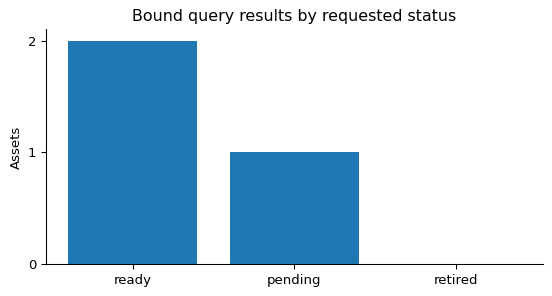

In [2]:
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE asset (name TEXT NOT NULL, state TEXT NOT NULL)")
db.executemany(
    "INSERT INTO asset VALUES (?,?)",
    [("workbook", "ready"), ("reader’s guide", "ready"), ("editor's copy", "pending")],
)
db.execute("PRAGMA query_only=ON")


def by_status(s):
    return [r[0] for r in db.execute("SELECT name FROM asset WHERE state=? ORDER BY name", (s,))]


assert db.execute("SELECT state FROM asset WHERE name=?", ("editor's copy",)).fetchone() == (
    "pending",
)
names = ["ready", "pending", "retired"]
counts = [len(by_status(s)) for s in names]
print("row counts", dict(zip(names, counts)))
assert counts == [2, 1, 0]
db.close()
fig, ax = plt.subplots(figsize=(5.7, 3), constrained_layout=True)
ax.bar(names, counts)
ax.set(ylabel="Assets", yticks=[0, 1, 2], title="Bound query results by requested status")
plt.show()

## Interpreting the result

An unknown status returns an empty result. Binding applies to values. A query builder that chooses column names needs a separate allowlist of identifiers.

## Exercise

Add a second bound condition and check a name with a space.

## References

[Python, sqlite3 parameter substitution](https://docs.python.org/3/library/sqlite3.html)